<a href="https://colab.research.google.com/github/zouhiraghenaim/Supervised-Learning-Algorithms/blob/main/TP4_Support_Vector_Machines/TP04_1_SVM___Supported_Vector_Machines.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **SVM — Support  Vector Machines**

**Support Vector Machine** (**SVM**) is a **Supervised Machine-Learning** algorithm primarily
used for classification problems. Its main objective is to find an **optimal decision**
**boundary** (**hyperplane**) that separates observations belonging to different classes while
maximizing **the margin** between the classes.
The observations located closest to the decision boundary are called **Support Vectors**.
These observations are particularly important because they determine the position of the
optimal separating hyperplane. **SVM** can also **handle more complex classification**
problems through the use of different **kernel functions**, which allow the model to construct
**nonlinear decision** boundaries

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn import svm

np.set_printoptions(precision=4, suppress=True)

 **1. Manually input the provided dataset into a Google Colab environment using Python
data structures (pandas DataFrame or numpy arrays).**

In [25]:
# url = "https://raw.githubusercontent.com/atman500/atman500/main/Simple%20_SVM.csv"
df = pd.DataFrame({
    "Observation": ["A", "B", "C", "D", "E", "F"],
    "X_1": [1, 2, 1, 4, 5, 4],   # Number of Late Payments
    "X_2": [1, 1, 2, 4, 4, 5],   # Credit Risk Level
    "Class": [-1, -1, -1, 1, 1, 1],
})

display(df.head())
print(f"\nShape: {df.shape}")


,Observation,X_1,X_2,Class
0,A,1,1,-1
1,B,2,1,-1
2,C,1,2,-1
3,D,4,4,1
4,E,5,4,1



Shape: (6, 4)


**2. Plot the initial observations on a 2D coordinate plane, utilizing distinct colors to
differentiate between the -1 and +1 classes**

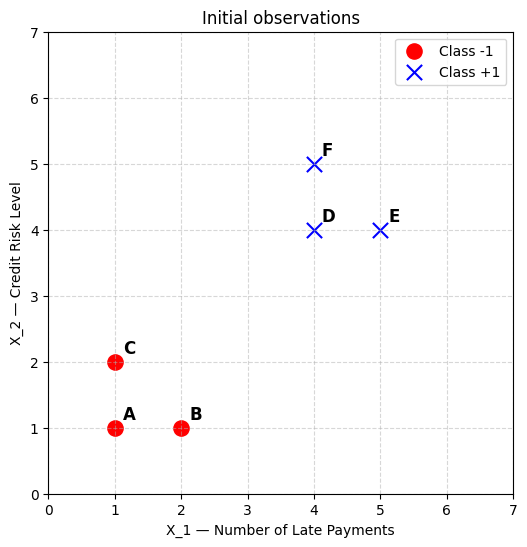

In [ ]:
neg = df[df["Class"] == -1]
pos = df[df["Class"] == 1]

plt.figure(figsize=(6, 6))
plt.scatter(neg["X_1"], neg["X_2"], color="red",  marker="o", s=120, label="Class -1")
plt.scatter(pos["X_1"], pos["X_2"], color="blue", marker="x", s=120, label="Class +1")
for _, row in df.iterrows():
    plt.annotate(row["Observation"], (row["X_1"] + 0.12, row["X_2"] + 0.12),
                 fontsize=12, fontweight="bold")
plt.xlabel("X_1 — Number of Late Payments")
plt.ylabel("X_2 — Credit Risk Level")
plt.title("Initial observations")
plt.xlim(0, 7); plt.ylim(0, 7)
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend()
plt.show()

**3. Build and train a Support Vector Machine (SVM) classifier with a linear kernel on
the dataset using scikit-learn**

In [ ]:
X = df[["X_1", "X_2"]]
y = df["Class"]

clf = svm.SVC(kernel="linear", C=1.0)
clf.fit(X, y)

w = clf.coef_[0]
b = clf.intercept_[0]

print(f"Weights (w)      : {w}")
print(f"Intercept (b)    : {b:+.4f}")
print(f"Decision boundary: {w[0]:+.4f}*X1 + {w[1]:+.4f}*X2 + ({b:+.4f}) = 0")

Weights (w)      : [0.4001 0.3999]
Intercept (b)    : -2.1999
Decision boundary: +0.4001*X1 + +0.3999*X2 + (-2.1999) = 0


**4. Extract and identify the Support Vectors computationally from your trained model,
and verify them against your visual geometric inspection.**

In [ ]:
sv_idx = clf.support_
sv_pts = clf.support_vectors_
f_vals = clf.decision_function(X)      # signed distance in margin units
preds  = clf.predict(X)

print(f"Support-vector indices : {sv_idx}")
print(f"Support-vector points  :\n{sv_pts}\n")
print("Matching observations:")
print(df.iloc[sv_idx].to_string(index=False))

print("\n--- decision_function values ---")
print(f"{'Obs':<4}{'(X1,X2)':<12}{'f(x)':>10}{'pred':>6}   {'status'}")
print("-" * 65)
for i, row in df.iterrows():
    f = f_vals[i]
    if   abs(f - 1) < 1e-6: status = "ON +margin  -> SUPPORT VECTOR"
    elif abs(f + 1) < 1e-6: status = "ON -margin  -> SUPPORT VECTOR"
    elif abs(f) < 1:        status = "inside margin"
    elif f > 0:             status = "beyond +margin"
    else:                   status = "beyond -margin"
    print(f"{row['Observation']:<4}{str((row['X_1'], row['X_2'])):<12}"
          f"{f:>10.4f}{preds[i]:>+6d}   {status}")

assert set(sv_idx) == {1, 2, 3}, "Unexpected support vectors!"
print("\n✓ Support vectors confirmed: B, C (class -1) and D (class +1).")

Support-vector indices : [1 2 3]
Support-vector points  :
[[2. 1.]
 [1. 2.]
 [4. 4.]]

Matching observations:
Observation  X_1  X_2  Class
          B    2    1     -1
          C    1    2     -1
          D    4    4      1

--- decision_function values ---
Obs (X1,X2)           f(x)  pred   status
-----------------------------------------------------------------
A   (1, 1)         -1.3999    -1   beyond -margin
B   (2, 1)         -0.9998    -1   inside margin
C   (1, 2)         -1.0001    -1   beyond -margin
D   (4, 4)          0.9999    +1   inside margin
E   (5, 4)          1.4000    +1   beyond +margin
F   (4, 5)          1.3998    +1   beyond +margin

✓ Support vectors confirmed: B, C (class -1) and D (class +1).


**5. Plot the Optimal Separating Hyperplane and the margin boundaries passing through
the identified Support Vectors.**

=== General form  w·x + b = k ===
Decision boundary : +0.4001*X1 + +0.3999*X2 + (-2.1999) = 0
Positive margin   : +0.4001*X1 + +0.3999*X2 + (-2.1999) = +1
Negative margin   : +0.4001*X1 + +0.3999*X2 + (-2.1999) = -1

=== Slope-intercept form  X2 = m*X1 + c ===
Decision boundary : X2 = -1.0006*X1 + +5.5016
Positive margin   : X2 = -1.0006*X1 + +8.0025
Negative margin   : X2 = -1.0006*X1 + +3.0008

Margin width 2/||w|| = 3.5357


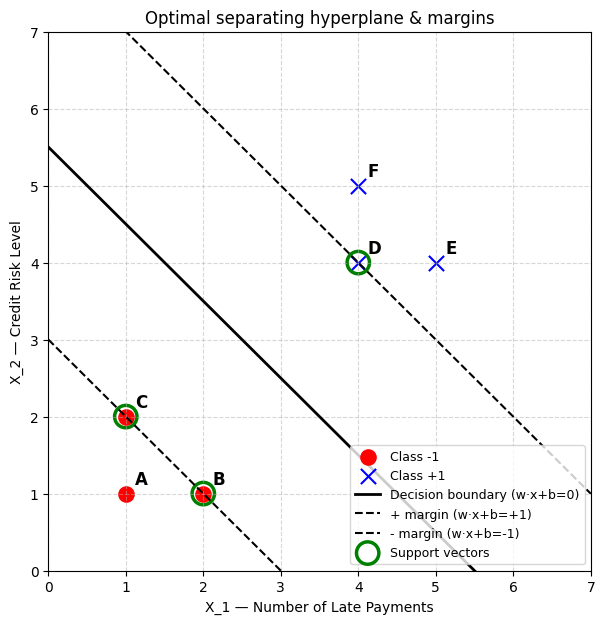

In [ ]:
# 5.a General form: w·x + b = k
print("=== General form  w·x + b = k ===")
print(f"Decision boundary : {w[0]:+.4f}*X1 + {w[1]:+.4f}*X2 + ({b:+.4f}) = 0")
print(f"Positive margin   : {w[0]:+.4f}*X1 + {w[1]:+.4f}*X2 + ({b:+.4f}) = +1")
print(f"Negative margin   : {w[0]:+.4f}*X1 + {w[1]:+.4f}*X2 + ({b:+.4f}) = -1")

# 5.b Slope–intercept form: X2 = m*X1 + c
slope = -w[0] / w[1]
c_dec = -b         / w[1]
c_pos = -(b - 1.0) / w[1]
c_neg = -(b + 1.0) / w[1]

print("\n=== Slope-intercept form  X2 = m*X1 + c ===")
print(f"Decision boundary : X2 = {slope:+.4f}*X1 + {c_dec:+.4f}")
print(f"Positive margin   : X2 = {slope:+.4f}*X1 + {c_pos:+.4f}")
print(f"Negative margin   : X2 = {slope:+.4f}*X1 + {c_neg:+.4f}")
print(f"\nMargin width 2/||w|| = {2.0 / np.linalg.norm(w):.4f}")

# 5.c Plot
plt.figure(figsize=(7, 7))
plt.scatter(neg["X_1"], neg["X_2"], color="red",  marker="o", s=120, label="Class -1")
plt.scatter(pos["X_1"], pos["X_2"], color="blue", marker="x", s=120, label="Class +1")
for _, row in df.iterrows():
    plt.annotate(row["Observation"], (row["X_1"] + 0.12, row["X_2"] + 0.12),
                 fontsize=12, fontweight="bold")

xx = np.linspace(0, 7, 200)
plt.plot(xx, slope * xx + c_dec, "k-",  lw=2.0, label="Decision boundary (w·x+b=0)")
plt.plot(xx, slope * xx + c_pos, "k--", lw=1.5, label="+ margin (w·x+b=+1)")
plt.plot(xx, slope * xx + c_neg, "k--", lw=1.5, label="- margin (w·x+b=-1)")

plt.scatter(sv_pts[:, 0], sv_pts[:, 1], s=260, facecolors="none",
            edgecolors="green", linewidths=2.5, label="Support vectors")

plt.xlim(0, 7); plt.ylim(0, 7)
plt.xlabel("X_1 — Number of Late Payments")
plt.ylabel("X_2 — Credit Risk Level")
plt.title("Optimal separating hyperplane & margins")
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend(loc="lower right", fontsize=9)
plt.show()

**6. Assuming feature X_1 represents "Number of Late Payments" and feature X_2
represents "Credit Risk Level," formulate a strategic business decision rule based
on the feature weights (coefficients) derived from the model.**

In [ ]:

# --- 6.1 Weights interpretation ---------------------------------
print("Feature weights:")
print(f"  w1 (Number of Late Payments) = {w[0]:+.4f}")
print(f"  w2 (Credit Risk Level)       = {w[1]:+.4f}")
print(f"  b  (intercept)               = {b:+.4f}")
print(f"\n|w1| ≈ |w2| → both features contribute EQUALLY to the decision.")
print(f"Both weights are positive → both push toward HIGH credit risk (+1).")

# --- 6.2 Mathematical rule --------------------------------------
threshold = -b / w[0]   # since w1 ≈ w2, decision ≈ X1 + X2 = threshold
print(f"\nDecision rule (mathematical):")
print(f"  {w[0]:+.4f}*X1 + {w[1]:+.4f}*X2 + ({b:+.4f}) > 0")
print(f"  ⟺  X1 + X2 > {threshold:.2f}   (approximately)")

# --- 6.3 Business rule ------------------------------------------
print("\nBusiness recommendation:")
print("  Flag a client for stricter credit conditions / human review")
print("  when   Number of Late Payments + Credit Risk Level  ≥  6.")
print("  (6 is used instead of 5.5 to add a safety buffer → fewer false positives.)")

# --- 6.4 Demonstration ------------------------------------------
print("\n--- Demonstration on hypothetical clients ---")
print(f"{'X1':>4}{'X2':>5}{'X1+X2':>8}{'f(x)':>12}{'prediction':>26}{'action':>28}")
print("-" * 83)

def classify_client(x1, x2):
    score = clf.decision_function([[x1, x2]])[0]
    label = "HIGH credit risk (+1)" if score > 0 else "LOW  credit risk (-1)"
    action = "Automatic rejection" if score > 0 else "Standard processing"
    return label, score, action

for x1, x2 in [(1, 1), (3, 2), (2, 3), (3, 3), (5, 5)]:
    label, score, action = classify_client(x1, x2)
    print(f"{x1:>4}{x2:>5}{x1 + x2:>8}{score:>12.4f}{label:>26}{action:>28}")

print("\nDone.")

Feature weights:
  w1 (Number of Late Payments) = +0.4001
  w2 (Credit Risk Level)       = +0.3999
  b  (intercept)               = -2.1999

|w1| ≈ |w2| → both features contribute EQUALLY to the decision.
Both weights are positive → both push toward HIGH credit risk (+1).

Decision rule (mathematical):
  +0.4001*X1 + +0.3999*X2 + (-2.1999) > 0
  ⟺  X1 + X2 > 5.50   (approximately)

Business recommendation:
  Flag a client for stricter credit conditions / human review
  when   Number of Late Payments + Credit Risk Level  ≥  6.
  (6 is used instead of 5.5 to add a safety buffer → fewer false positives.)

--- Demonstration on hypothetical clients ---
  X1   X2   X1+X2        f(x)                prediction                      action
-----------------------------------------------------------------------------------
   1    1       2     -1.3999     LOW  credit risk (-1)         Standard processing
   3    2       5     -0.1999     LOW  credit risk (-1)         Standard processing
   2    

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but SVC was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but SVC was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but SVC was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but SVC was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but SVC was fitted with feature names
  warnings.warn(


#  Summary


## 3. Outputs
*   **Feature Weights:** \(w_1 = 0.4001\), \(w_2 = 0.3999\).
*   **Bias (Intercept):** \(b = -2.1999\).
*   **Decision Boundary (Hyperplane):** \(0.4001X_1 + 0.3999X_2 - 2.1999 = 0\) (simplified to \(X_1 + X_2 \approx 5.5\)).
*   **Support Vectors:** Points **B, C, and D** (these specific data points dictate the position of the margins).

## 4. Economic & Business Interpretation
*   **Equal Feature Importance:** Since \(|w_1| \approx |w_2|\), both the "Number of Late Payments" and "Credit Risk Level" contribute almost equally to the risk assessment. Both features positively push the client towards the High-Risk category.
*   **Business Decision Rule:** While the mathematical boundary is 5.5, management established a **safety buffer of 6**. Any client with \(X_1 + X_2 \ge 6\) is flagged as High Risk (Automatic rejection or human review).
*   **Strategic Goal:** This buffer minimizes "False Positives" (rejecting good clients) while strictly protecting the company's portfolio from high-risk defaults.